# Homework 1: Social Network Analysis

In [1]:
import numpy as np
import scipy.sparse as ssp
from graphLib import Graph
from itertools import combinations
import matplotlib.pyplot as plt

## Example

In [2]:
#--- read the graph file and construct a graph
graph = Graph(ssp.load_npz('../data/example_graph.npz'))

In [3]:
# number of nodes in graph:
n = graph.n
print(n)

10


In [4]:
# get the adjacency matrix of graph

A = graph.get_adj_matrix()
print(A)

[[0 0 0 0 1 0 1 1 0 0]
 [0 0 1 0 0 0 0 0 1 0]
 [0 1 0 0 0 1 1 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [1 0 0 1 0 1 1 0 0 1]
 [0 0 1 0 1 0 0 0 0 0]
 [1 0 1 0 1 0 0 1 0 1]
 [1 0 0 0 0 0 1 0 0 1]
 [0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 1 1 0 0]]


In [5]:
# get adjacency list

adj_list = graph.get_adj_list()
for i in range(n):
	print(i, adj_list[i])

0 [np.int64(4), np.int64(6), np.int64(7)]
1 [np.int64(2), np.int64(8)]
2 [np.int64(1), np.int64(5), np.int64(6)]
3 [np.int64(4)]
4 [np.int64(0), np.int64(3), np.int64(5), np.int64(6), np.int64(9)]
5 [np.int64(2), np.int64(4)]
6 [np.int64(0), np.int64(2), np.int64(4), np.int64(7), np.int64(9)]
7 [np.int64(0), np.int64(6), np.int64(9)]
8 [np.int64(1)]
9 [np.int64(4), np.int64(6), np.int64(7)]


In [6]:
# get degree sequence

deg_seq = graph.get_deg_seq()
print(deg_seq)

[3 2 3 1 5 2 5 3 1 3]


## Task 1: Compute Graph Properties [45 points]

In [7]:
from task_1 import compute_deg_distr, get_cc_local, get_cc_global, get_diameter

### Task 1.1: Degree Distribution

In [8]:
#--- read the graph file and construct a graph
G1 = Graph(ssp.load_npz('../data/graph_ER.npz'))   # Erdos-Renyi graph, p = 0.3
G2 = Graph(ssp.load_npz('../data/graph_BA.npz'))   # Barabasi-Albert graph

In [9]:
#--- obtain degree sequence and associated counts
degs1,counts1=compute_deg_distr(G1)
degs2,counts2=compute_deg_distr(G2)

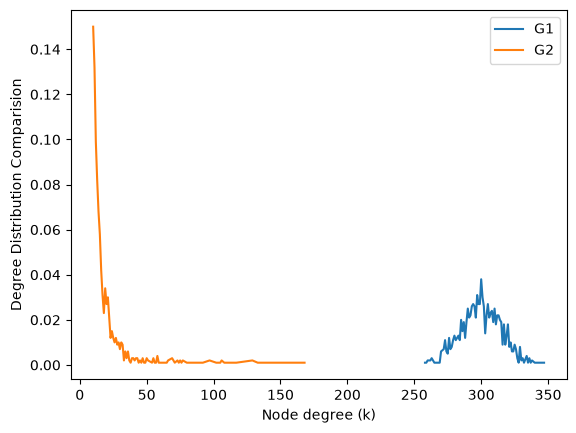

In [10]:
#--- plot the degree distribution
Pk1=counts1/G1.n
Pk2=counts2/G2.n
plt.plot(degs1, Pk1, label='G1')
plt.plot(degs2, Pk2, label='G2')
plt.xlabel('Node degree (k)')
plt.ylabel('P(k)')
plt.ylabel('Degree Distribution Comparision')
plt.legend()
plt.show()

### Task 1.2: Clustering Coefficients

In [11]:
for i in [0,5]:
    print(get_cc_local(graph,i))

0.6666666666666666
0.0


In [12]:
cc_global = get_cc_global(graph)

In [13]:
print(cc_global)

0.35294117647058826


### Task 1.3: Graph Diameter

In [14]:
diameter = get_diameter(graph)

In [15]:
print(diameter)

5


## Task 2: Compute Node Centralities [35 points]

In [16]:
from task_2 import get_eigen_centrality, build_matrix, get_btw_c

### Task 2.1: Eigenvector Centrality

In [17]:
# TODO: find the top-10 nodes and their eigenvector centralities
centralities = get_eigen_centrality(graph)

top_10 = np.argsort(centralities)[-10:][::-1]

for node in top_10:
    print(node, centralities[node])

6 0.5134597430289777
4 0.4554175066446736
0 0.3800315840746413
9 0.3800315840746413
7 0.363299371553697
2 0.22112052578547492
5 0.19299679641149695
3 0.1299174851950524
1 0.06866744306265425
8 0.019588841858982183


In [18]:
eigenvector = get_eigen_centrality(graph)

### Task 2.2: Betweenness Centrality

In [19]:
# build 2 global matrices: a distance matrix, and a matrix storing the number of shortest pathes
n = graph.n
distance_mat = np.zeros((n,n), dtype = int)
num_shortest_path_mat = np.zeros((n,n), dtype = int)

In [20]:
# construct the two matrices - it is recommended you save the two matrices into files since they 
# take a lot of time to compute 
build_matrix(graph,distance_mat,num_shortest_path_mat)
np.save('distance_mat.npy', distance_mat)
np.save('num_shortest_path_mat.npy', num_shortest_path_mat)

In [21]:
# TODO: compute the betweenness centrality for each node
betweenness_centrality = np.zeros(graph.n)
for w in range(graph.n):
    betweenness_centrality[w] = get_btw_c(graph, w, distance_mat, num_shortest_path_mat)

for i in range(graph.n):
    print(i, betweenness_centrality[i])

0 0.02546296296296296
1 0.2222222222222222
2 0.4097222222222222
3 0.0
4 0.3217592592592593
5 0.08333333333333333
6 0.37500000000000006
7 0.009259259259259259
8 0.0
9 0.02546296296296296


In [22]:
# compute centrality for node 0 (this is just an example)
centrality = get_btw_c(graph, 0, distance_mat, num_shortest_path_mat)
print(centrality)

0.02546296296296296


## Task 3: Link Prediction [20 points]

In [23]:
from task_3 import gen_net_obs, compute_Jaccard, compute_Katz, link_pred

graph = Graph(ssp.load_npz('../data/ws_graph.npz'))

# load the test edges and non_edges
test_edges = np.loadtxt('../data/target.edges',dtype = int)
test_non_edges = np.loadtxt('../data/target.nonedges', dtype = int)
pos_num = len(test_edges)
neg_num = len(test_non_edges)

# 1 denotes an edge; 0 denotes a non-edge
ground_truth = np.concatenate((np.ones(pos_num,dtype = int),np.zeros(neg_num,dtype = int)), axis = 0)

In [24]:
# TODO: generate observed network
gen_net_obs(graph, test_edges, test_non_edges)

(array([[0, 1, 0, ..., 1, 1, 1],
        [1, 0, 1, ..., 0, 1, 1],
        [0, 1, 0, ..., 1, 1, 1],
        ...,
        [1, 0, 1, ..., 0, 1, 1],
        [1, 1, 1, ..., 1, 0, 0],
        [1, 1, 1, ..., 1, 0, 0]], shape=(1000, 1000)),
 array([[398, 403],
        [774, 939],
        [229, 854],
        [226, 228],
        [137, 141],
        [516, 973],
        [ 47,  49],
        [ 74, 545],
        [202, 204],
        [916, 920],
        [437, 773],
        [140, 142],
        [597, 600],
        [939, 941],
        [976, 981],
        [753, 755],
        [611, 613],
        [672, 674],
        [  9, 760],
        [433, 895],
        [512, 827],
        [230, 490],
        [197, 442],
        [103, 105],
        [200, 843],
        [699, 702],
        [734, 738],
        [712, 716],
        [ 48, 238],
        [565, 569],
        [559, 578],
        [374, 375],
        [545, 644],
        [747, 998],
        [780, 784],
        [430, 780],
        [433, 559],
        [511, 513],
       

In [25]:
adj_obs, test_set = gen_net_obs(graph, test_edges,test_non_edges)

In [26]:
# TODO: Get similarity based on metric (Katz or Jaccard)

In [27]:
jaccardsim = compute_Jaccard(adj_obs,test_set)
np.savetxt('../result/Jac_sim.txt', jaccardsim, fmt = '%f')

In [28]:
katzsim = compute_Katz(adj_obs,test_set)
np.savetxt('../result/Katz_sim.txt', katzsim, fmt = '%f')

In [29]:
# TODO: make prediction

In [30]:
pred_jac=link_pred(adj_obs, test_set, 'Jaccard',0.1)
pred_katz=link_pred(adj_obs, test_set, 'Katz',0.02)

[0.06313056 0.00592195 0.00655018 0.09757632 0.05764986 0.00503732
 0.03022133 0.00505597 0.06699864 0.02468361 0.00447424 0.04369612
 0.1271671  0.08083046 0.0501744  0.04369848 0.10581995 0.08092862
 0.00438182 0.00350178 0.00654002 0.00409662 0.00529254 0.06429546
 0.00670136 0.04662396 0.01976659 0.05446512 0.00578964 0.04459472
 0.00535118 0.02230294 0.00358962 0.0073622  0.05790127 0.00359695
 0.00325373 0.08785039 0.00483554 0.00948636 0.00289198 0.01525096
 0.02649455 0.00994969 0.0358664  0.03444848 0.05087416 0.03384075
 0.00437993 0.06119711 0.02639547 0.03932717 0.00357545 0.05416656
 0.03229394 0.0073268  0.05665963 0.05324946 0.05946418 0.00822669
 0.127896   0.00381469 0.05026136 0.07680161 0.03472457 0.00699351
 0.01879888 0.02586053 0.00389699 0.03369276 0.08878632 0.00510803
 0.0063768  0.1105745  0.04896695 0.05626311 0.10821206 0.00261493
 0.02193564 0.05555042 0.05868836 0.02363903 0.00474952 0.03991276
 0.00695431 0.05009333 0.00721427 0.01883751 0.01918681 0.0723

In [34]:
# TODO: compute accuracy based on pred and groundtruth
# accuracy  =  correctly predicted node pairs/total number of pairs
ground_truth = np.concatenate([
    np.ones(len(test_edges)),
    np.zeros(len(test_non_edges))
])
print(ground_truth.shape)

acc_jac=np.sum(pred_jac==ground_truth) / len(ground_truth)
print(acc_jac)

acc_katz = np.sum(pred_katz==ground_truth) / len(ground_truth)
print(acc_katz)

(200,)
0.725
0.775


In [35]:
print(len(test_edges))
print(len(test_non_edges))
print(test_edges.shape if hasattr(test_edges, 'shape') else type(test_edges))
print(test_non_edges.shape if hasattr(test_non_edges, 'shape') else type(test_non_edges))
print(pred_jac.shape)
print(pred_katz.shape)
print(jaccardsim.min(), jaccardsim.max())
print(katzsim.min(), katzsim.max())
print(np.unique(pred_jac, return_counts=True))
print(np.unique(pred_katz, return_counts=True))

100
100
(100, 2)
(100, 2)
(200,)
(200,)
0.0 0.5
0.0023861008993959483 0.12789599836783344
(array([0, 1]), array([153,  47]))
(array([0, 1]), array([141,  59]))


## Task 4: Generate Random Graphs [20 points]

### Task 4.1: Erdos-Renyi Graph [10 points]

In [ ]:
from task_4 import gen_ER, gen_BA

In [ ]:
# parameters - DO NOT CHANGE the seed
seed = 14
n = 200
p = 0.2
m = 5

# TODO: get the adj matrix A for erdos-renyi graphs
A_ER = gen_ER(n,p,seed)

# save the matrix A into file
ssp.save_npz('../result/task_4_graph_ER.npz', ssp.csr_matrix(A))

In [ ]:
degs_sorted = np.sort(sum(A_ER))

plt.plot(range(len(degs_sorted)),degs_sorted,'bo')
plt.ylabel('Degrees')
plt.show()

### Task 4.1: Erdos-Renyi Graph [10 points]

In [ ]:
# TODO: get the adj matrix A for BA graphs
A_BA = gen_BA(n,m,seed)

# save the matrix A into file
ssp.save_npz('../result/task_4_graph_BA.npz', ssp.csr_matrix(A))

### Task 4.2: Erdos-Renyi Graph [10 points]

In [ ]:
degs_sorted = np.sort(sum(A_BA))

plt.plot(range(len(degs_sorted)),degs_sorted,'bo')
plt.ylabel('Degrees')
plt.show()

## Task 5: Influence Maximization and Blocking [30 points]

In [ ]:
# parameters: DO NOT CHANGE
p = 0.05
mc = 5000
#k=10
k = 1

In [ ]:
from task_5 import greedySearch, modify_graph

In [ ]:
graph = Graph(ssp.load_npz('../data/example_graph.npz'))
#graph = Graph(ssp.load_npz('../data/BA_graph_100.npz'))

In [ ]:
seeds, influence = greedySearch(graph,k,p,mc)

In [ ]:
# we recommend saving the results into files
#np.savetxt('../result/IM_seeds.txt', seeds, fmt = '%s')
#np.savetxt('../result/IM_influence.txt', influence, fmt = '%f')

# uncomment these lines if you want to read the values instead of recalculating them 
# seeds = np.loadtxt('../result/IM_seeds.txt', dtype = int)
# influence = np.loadtxt('../result/IM_influence.txt', dtype = float)

In [ ]:
# randomly select nn nodes; DO NOT CHANGE nn=50 BELOW
#nn=50
nn=10
np.random.seed(15)
target_nodes = np.random.choice(range(graph.n), nn, replace = False)

# each node in seed_set will randomly block a neighbor 
# equivalently, delete the edge between that node and the neighbor

# create a modified graph
graph_new = Graph(modify_graph(graph,target_nodes))

# TODO: compute the seeds and influences over the new graph using the same parameters
seeds_new, influence_new = greedySearch(graph_new,k,p,mc)

#np.savetxt('../result/IM_seeds_new.txt', seeds_new, fmt = '%s')
#np.savetxt('../result/IM_influence_new.txt', influence_new, fmt = '%f')

# uncomment these lines if you want to read the values instead of recalculating them 
# seeds_new = np.loadtxt('../result/IM_seeds_new.txt', dtype = int)
# influence_new = np.loadtxt('../result/IM_influence_new.txt', dtype = float)

# plot in the same figure
plt.plot(range(k+1), influence,'-bo',range(k+1), influence_new,'-rs')
plt.show()